Evaluacion de desempeño (MSE)

Polinomio grado 10 (Sin regularizacion) -> Test MSE: 0.0277
Polinomio grado 10 (Con Lasso L1) -> Test MSE: 0.1073


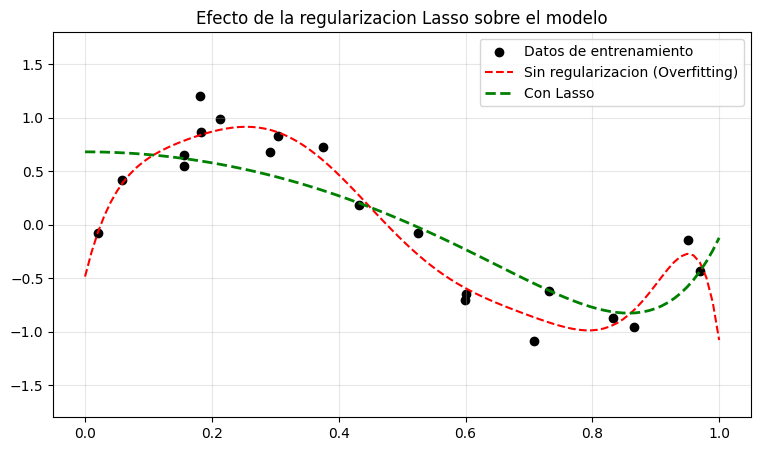

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import  PolynomialFeatures#oncvertir unas varialbes en caracgersticas polinomicas 
from sklearn.linear_model import LinearRegression,Lasso#de aqui tambien sale 'redge' 
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

#crear grupo de datos con curva seno + ruido
np.random.seed(42)
x=np.sort(np.random.rand(20))#lo q hace es crear 20 numeros aleatoricos decimales entre 20 y 1 tambien ordenarlo de menor a mayor 
y=np.sin(2*np.pi*x)+np.random.normal(0,0.2,20)#lo q hace es, creand los valores de y,creando un curva seno
#convierte x en una matriz de una sola columna 
X=x[:,np.newaxis]
#crea 100 valores uniforme separados entre 0 y 1, qui los numeros no son aleatorios y normalmente tienen la misma separacion
X_test=np.linspace(0,1,100)[:,np.newaxis]
Y_test=np.sin(2*np.pi*X_test.ravel())#calcular los valores reales de la funcion seno, -- oncvirete en ua matriz de 

#entrenar el polinomio de grado 10 (SobreAjuste/Overfitting)
modelo_overfit=make_pipeline(
    
    PolynomialFeatures(degree=10),#transforma la variable en un polinomio de grado 10
    LinearRegression()
    
)

#entrenando el modelo de grado 10
modelo_overfit.fit(X,y)

#aplica regularizacion Lasso L1, AYUDA A REDICRU LA VARIANZA, quee l modelo no se apadata tanto a los modelos de entrenamiento
modelo_lasso=make_pipeline(
    
    PolynomialFeatures(degree=10),
    Lasso(alpha=0.01,random_state=42),# es el valor que regula el valor del coeficiente 
    
    
)

modelo_lasso.fit(X,y)

print("Evaluacion de desempeño (MSE)")
print()
#y_Test son los verdaders la cruva de seno sin el ruido
#los valores que predice el modelo
print(f"Polinomio grado 10 (Sin regularizacion) -> Test MSE: {mean_squared_error(Y_test,modelo_overfit.predict(X_test)):.4f}")
print(f"Polinomio grado 10 (Con Lasso L1) -> Test MSE: {mean_squared_error(Y_test,modelo_lasso.predict(X_test)):.4f}")

#graficar la comparacion 
plt.figure(figsize=(9,5))
#grafico de dispersion
plt.scatter(
    
    X,
    y,
    color='black',
    label='Datos de entrenamiento',
    
    
)

plt.plot(
    
    X_test,
    modelo_overfit.predict(X_test),
    'r--',#aspecto q va a tener la linea punteaguda roja
    label='Sin regularizacion (Overfitting)',
    
)

plt.plot(
    
    X_test,
    modelo_lasso.predict(X_test),
    'g--',
    linewidth=2,#mas marcada la linea
    label='Con Lasso'
    
)

#inferior , superior
plt.ylim(-1.8,1.8)
plt.title('Efecto de la regularizacion Lasso sobre el modelo')
plt.legend()
plt.grid(True,alpha=0.3)
plt.show()